# 06 · A local replay of the evaluation, and the baselines to beat

The official evaluator replays a full year of requests that we cannot see. To compare ideas we
need the same game on data we *can* see: a **local replay** that applies the evaluator's rules to
2016, with the policy trained only on what happened before.

**How the replay works** (`src/simulator.py`):

1. **Inputs at the start of the window.** `commitments` = window arrivals booked before the window
   starts (already confirmed, outcome hidden); `capacity` = rooms minus guests who arrived earlier
   and are still in house, for every night.
2. **Requests.** Every other booking of the window is passed to `decide()` once, in booking-date
   order. Same-day requests come in **random order** (notebook 01: ordering by id would leak the
   outcome); three different seeds are used to measure the noise.
3. **Check-in.** Day by day, the guests who show up are seated; when the hotel is full the
   cheapest arriving guests are walked: no revenue, penalty 2.5 × stay value.

Any policy with the `Solution` interface (`__init__(commitments, capacity)`, `decide(booking)`)
plugs in unchanged, including the final deliverable. Policies that learn from data only see
`ho.history` (arrivals before the window).

In [1]:
import sys
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, build_holdout, evaluate_local, run_policy, score, check_in, ROOMS
from src.baselines import AcceptAll, RejectAll, LoadLimit, ExpectedShows, oracle_accept
from src import plotting as P

P.setup()
pd.set_option("display.width", 160)
df = load_train()
ho = build_holdout(df, 2016)
pd.DataFrame({
    "commitments": ho.commitments.hotel.value_counts(),
    "requests in 2016": ho.requests.hotel.value_counts(),
    "free rooms on 1 Jan": {h: s.iloc[0] for h, s in ho.capacity.items()},
    "free rooms on 1 Feb": {h: s.loc["2016-02-01"] for h, s in ho.capacity.items()},
})

,commitments,requests in 2016,free rooms on 1 Jan,free rooms on 1 Feb
Downtown Hotel,8225,29722,0,124
Seaside Hotel,3818,14525,0,103


On 1 January both hotels are full of guests who arrived in late December; a month later all rooms
are free. Every 2016 request (44k) goes through `decide()`.

## 1 · Baselines

| Strategy | Rule | What it represents |
|---|---|---|
| **Reject all** | always `False` | what the commitments alone are worth |
| **Accept all** | always `True` | no control at all |
| **No overbooking** | first come first served while booked rooms ≤ free rooms on every night | a cautious hotel without a model |
| **Overbooking at the average rate** | first come first served while Σ (1 − hotel cancel rate) ≤ free rooms | classic overbooking, one probability per hotel |
| **Overbooking by group** | as above, cancel rate per hotel × one column (segment, channel, guest type, agent, meal) | the simplest rule that uses a feature |
| **Oracle** *(cheats)* | knows who shows up; picks the highest rates until the hotel is full | how much is left on the table |

In [2]:
GROUPINGS = {"segment": "sales_segment", "channel": "sales_channel", "guest type": "guest_type",
             "agent": "agent", "meal": "meal"}
policies = {
    "Reject all": RejectAll,
    "Accept all": AcceptAll,
    "No overbooking": LoadLimit,
    "Overbooking at average rate": partial(ExpectedShows, history=ho.history),
    **{f"Overbooking by {k}": partial(ExpectedShows, history=ho.history, by=col) for k, col in GROUPINGS.items()},
}
per_hotel = {name: evaluate_local(f, ho) for name, f in policies.items()}
per_hotel["Oracle (cheats)"] = score(ho, oracle_accept(ho))
per_hotel = pd.concat(per_hotel, names=["strategy"]).droplevel(1)

cols = ["accepted", "revenue", "walk", "penalties", "net", "empty_room_nights"]
tot = per_hotel.groupby("strategy", sort=False)[cols].sum()
tot.assign(**{c: tot[c] / 1e6 for c in ["revenue", "penalties", "net"]}).round(3) \
   .rename(columns={"revenue": "revenue (M€)", "penalties": "penalties (M€)", "net": "net (M€)"})

,accepted,revenue (M€),walk,penalties (M€),net (M€),empty_room_nights
strategy,,,,,,
Reject all,0,1.690,264,0.143,1.547,61062
Accept all,44247,7.859,17409,9.537,-1.678,4805
No overbooking,14412,3.934,264,0.143,3.790,35361
Overbooking at average rate,25072,5.991,1967,0.734,5.257,14912
Overbooking by segment,22775,5.669,1129,0.453,5.216,16936
Overbooking by channel,25541,6.078,2191,0.825,5.252,14238
Overbooking by guest type,25523,6.042,2187,0.813,5.229,14553
Overbooking by agent,21462,5.416,715,0.291,5.124,19573
Overbooking by meal,23734,5.802,1230,0.483,5.319,16485


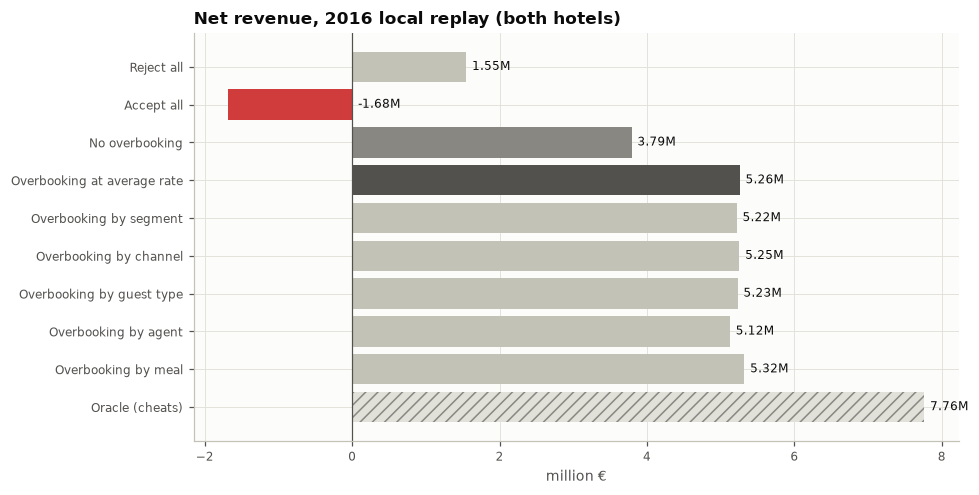

net                         walk              
hotel                       Downtown Hotel Seaside Hotel Downtown Hotel Seaside Hotel
strategy                                                                             
Reject all                          747231        799432            128           136
Accept all                         -749069       -929324          11017          6392
No overbooking                     2056698       1733433            128           136
Overbooking at average rate        2999389       2257794           1628           339
Overbooking by segment             3016527       2199885            509           620
Overbooking by channel             2976190       2276278           1846           345
Overbooking by guest type          2971292       2257369           1881           306
Overbooking by agent               2891231       2232941            424           291
Overbooking by meal                3075434       2243726            923           307
Oracle (cheats)                    4646401       3114394            128           136

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [P.LIGHT, P.CRITICAL, P.MUTED, P.INK_2] + [P.LIGHT] * len(GROUPINGS) + [P.GRID]
v = tot.net / 1e6
bars = ax.barh(v.index[::-1], v[::-1], color=colors[::-1])
bars[0].set_hatch("///"); bars[0].set_edgecolor(P.MUTED)          # oracle: not achievable
for i, x in enumerate(v[::-1]):
    ax.text(max(x, 0) + .08, i, f"{x:.2f}M", va="center", fontsize=8)
ax.axvline(0, color=P.INK_2, lw=.8)
ax.set(title="Net revenue, 2016 local replay (both hotels)", xlabel="million €")
P.save(fig, "baselines")
plt.tight_layout(); plt.show()
per_hotel.pivot_table(index="strategy", columns="hotel", values=["net", "walk"], sort=False).round(0).astype(int)

* **Accept all loses money** (−1.7M): 17k walks, each costing 2.5× what the stay would have earned.
* **No overbooking** is safe but leaves 35k room-nights empty, because one booking in three
  cancels: 3.79M. (Its 264 walks come from the commitments alone, on nights that were already
  over capacity.)
* **Overbooking with one cancellation rate per hotel** adds +1.47M: **5.26M**. This is the
  baseline to beat.
* **Splitting the rate by one column adds almost nothing** (5.12–5.32M). Some variants halve the
  walks but leave more rooms empty. An average rate per group cannot decide *who* to overbook.
* The **oracle** reaches 7.76M: about 2.5M of headroom for a model that estimates each booking's
  probability and chooses whom to accept.

## 2 · How much to overbook? A fixed factor

Variant of *No overbooking*: accept while booked rooms ≤ `k` × free rooms. The best `k` is
chosen **looking at the 2016 result**, so the curve is optimistic: it only shows the shape.

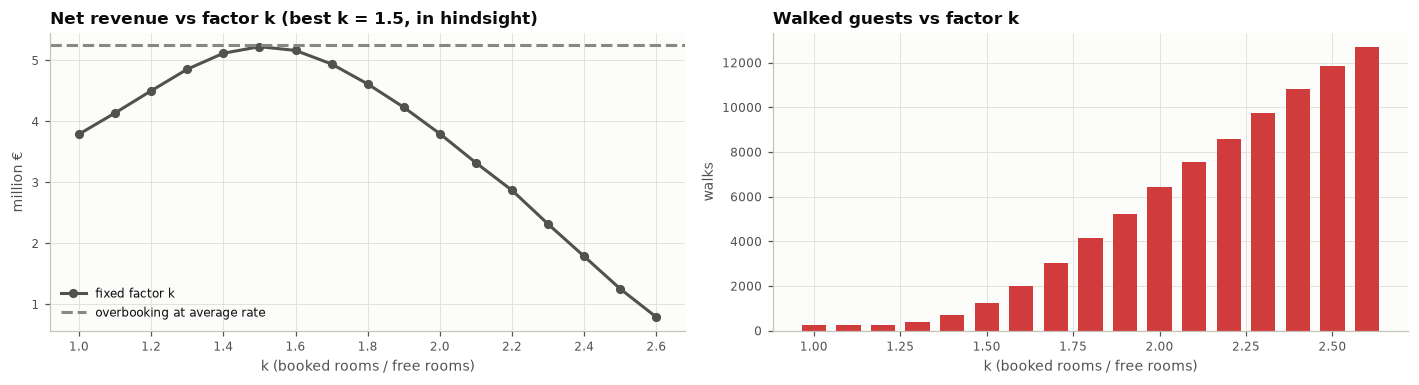

,net,walk
1.0,3.79,264.0
1.3,4.86,392.0
1.5,5.22,1242.0
2.0,3.80,6446.0
2.5,1.25,11839.0


In [4]:
ks = np.round(np.arange(1.0, 2.61, .1), 2)
sweep = pd.DataFrame([evaluate_local(partial(LoadLimit, factor=k), ho)[["net", "walk"]].sum().rename(k) for k in ks])
best = sweep.net.idxmax()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))
ax.plot(sweep.index, sweep.net / 1e6, marker="o", color=P.INK_2, label="fixed factor k")
ax.axhline(tot.loc["Overbooking at average rate", "net"] / 1e6, color=P.MUTED, ls="--", label="overbooking at average rate")
ax.set(title=f"Net revenue vs factor k (best k = {best}, in hindsight)", xlabel="k (booked rooms / free rooms)",
       ylabel="million €")
ax.legend(loc="lower left")
ax2.bar(sweep.index, sweep.walk, width=.07, color=P.CRITICAL)
ax2.set(title="Walked guests vs factor k", xlabel="k (booked rooms / free rooms)", ylabel="walks")
plt.tight_layout(); plt.show()
sweep.loc[sorted({1.0, 1.3, 1.5, best, 2.0, 2.5})].assign(net=lambda d: (d.net / 1e6).round(2))

Even with hindsight a single factor peaks around k ≈ 1.5 (5.2M) and then collapses: past the peak
every extra booking costs 2.5× in walks. The right amount of overbooking depends on the hotel, the
season and the booking, which is why the system estimates a probability **per booking**.

## 3 · Where do the baselines lose money?

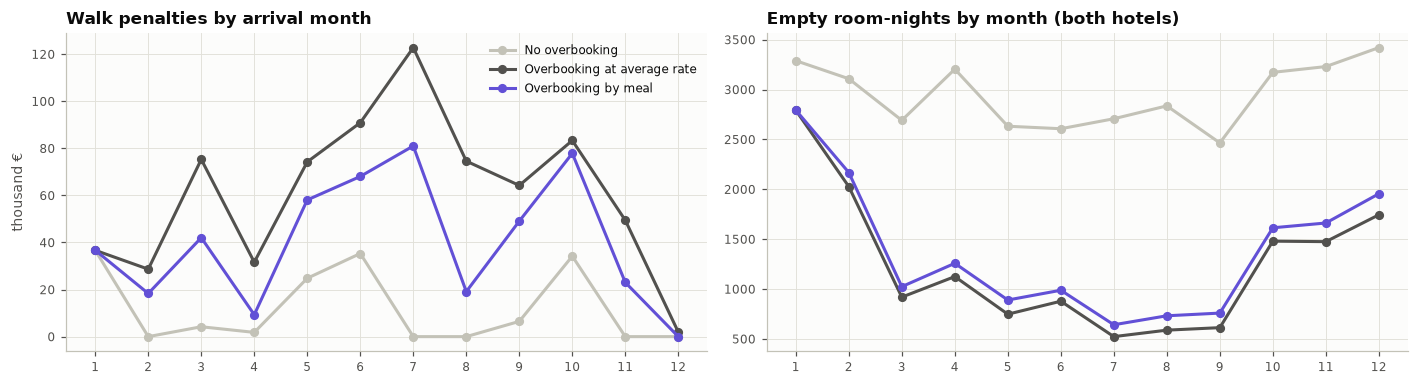

In [5]:
def monthly(accepted):
    g = check_in(ho, accepted)
    walk_pen = g[~g.seated].groupby(g.arrival_date.dt.month).penalty.sum()
    empty = 0
    for h in ROOMS:
        used = np.zeros(len(ho.days))
        x = g[(g.hotel == h) & g.seated]
        for s, e in zip(x.start, x.end):
            used[s:e] += 1
        empty = empty + pd.Series((ho.capacity[h].to_numpy() - used).clip(0), index=ho.days)
    return walk_pen.reindex(range(1, 13), fill_value=0), empty.groupby(ho.days.month).sum()


show = {"No overbooking": P.LIGHT, "Overbooking at average rate": P.INK_2, "Overbooking by meal": P.VIOLET}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name, c in show.items():
    pen, empty = monthly(run_policy(policies[name], ho)[0])
    axes[0].plot(pen.index, pen / 1e3, marker="o", color=c, label=name)
    axes[1].plot(empty.index, empty, marker="o", color=c, label=name)
axes[0].set(title="Walk penalties by arrival month", ylabel="thousand €", xticks=range(1, 13))
axes[1].set(title="Empty room-nights by month (both hotels)", xticks=range(1, 13))
axes[0].legend()
plt.tight_layout(); plt.show()

The two kinds of loss sit in different places. Without overbooking, 2,500–3,500 room-nights stay
empty **every month**. With overbooking the empty rooms shrink from March to September but stay
high in the low season, while walks concentrate in summer and October, when the accepted guests
cancel less than the historical average. A per-booking probability can move the overbooking to
where it pays.

## Summary: the numbers to beat (2016 replay)

| Strategy | Net 2016 |
|---|---|
| Accept all | −1.68M |
| No overbooking | 3.79M |
| **Overbooking at the average rate per hotel** | **5.26M** (baseline to beat) |
| Overbooking by one column | 5.12–5.32M |
| Oracle (cheats) | 7.76M |

The final system is evaluated with exactly the same call, `evaluate_local(Solution, ho)`
(notebook 08).